In [46]:
files_to_check = [

    MODELS_DIR /
    "cgan_generator.keras",

    MODELS_DIR /
    "cgan_discriminator.keras",

    SYNTHETIC_DIR /
    "cgan_fraud_synthetic.parquet",

    PROCESSED_DIR /
    "X_train_cgan.parquet",

    PROCESSED_DIR /
    "y_train_cgan.parquet",

    METRICS_DIR /
    "cgan_training_history.csv",

    METRICS_DIR /
    "cgan_feature_fidelity.csv",

    METRICS_DIR /
    "cgan_summary.csv",

    FIGURES_DIR /
    "cgan_training_losses.png",

    FIGURES_DIR /
    "cgan_time_v1_iteration_1_vs_5000.png",

    FIGURES_DIR /
    "cgan_pca_iteration_1_vs_5000.png",

    FIGURES_DIR /
    "cgan_conditioning_effect.png",

    FIGURES_DIR /
    "cgan_pca_real_vs_synthetic.png"
]

for path in files_to_check:

    print(
        path.name,
        "→",
        path.exists()
    )

cgan_generator.keras → True
cgan_discriminator.keras → True
cgan_fraud_synthetic.parquet → True
X_train_cgan.parquet → True
y_train_cgan.parquet → True
cgan_training_history.csv → True
cgan_feature_fidelity.csv → True
cgan_summary.csv → True
cgan_training_losses.png → True
cgan_time_v1_iteration_1_vs_5000.png → True
cgan_pca_iteration_1_vs_5000.png → True
cgan_conditioning_effect.png → True
cgan_pca_real_vs_synthetic.png → True


In [45]:
cgan_history.to_csv(
    METRICS_DIR /
    "cgan_training_history.csv",
    index=False
)

cgan_fidelity.to_csv(
    METRICS_DIR /
    "cgan_feature_fidelity.csv",
    index=False
)

cgan_summary.to_csv(
    METRICS_DIR /
    "cgan_summary.csv",
    index=False
)

In [44]:
X_train_cgan.to_parquet(
    PROCESSED_DIR /
    "X_train_cgan.parquet",
    index=False
)

y_train_cgan.to_frame(
    name="Class"
).to_parquet(
    PROCESSED_DIR /
    "y_train_cgan.parquet",
    index=False
)

In [43]:
cgan_synthetic_df = (
    X_cgan_synthetic.copy()
)

cgan_synthetic_df[
    "Class"
] = 1

cgan_synthetic_df.to_parquet(
    SYNTHETIC_DIR /
    "cgan_fraud_synthetic.parquet",
    index=False
)

In [42]:
cgan_generator.save(
    MODELS_DIR /
    "cgan_generator.keras"
)

cgan_discriminator.save(
    MODELS_DIR /
    "cgan_discriminator.keras"
)

In [40]:
cgan_summary = pd.DataFrame({
    "Mesure": [
        "Normales réelles Train",
        "Fraudes réelles Train",
        "Dimension du bruit",
        "Itérations CGAN",
        "Fraudes synthétiques créées",
        "NaN synthétiques",
        "Inf synthétiques",
        "Doublons synthétiques",
        "Copies exactes",
        "Valeurs hors bornes fraude",
        "Diversité réelle",
        "Diversité CGAN",
        "Ratio diversité CGAN/Réel",
        "Différence condition 0/1",
        "Erreur corrélation Spearman",
        "Médiane NN réel→réel",
        "Médiane NN CGAN→réel"
    ],
    "Valeur": [
        len(X_real_normal),
        len(X_real_fraud),
        LATENT_DIM,
        N_STEPS,
        len(X_cgan_synthetic),
        cgan_nan,
        cgan_inf,
        cgan_duplicates,
        cgan_exact_copies,
        cgan_outside_count,
        real_diversity,
        cgan_diversity,
        cgan_diversity_ratio,
        conditional_difference,
        cgan_corr_mae,
        np.median(
            real_reference_nn
        ),
        np.median(
            synthetic_nn_distances
        )
    ]
})

display(
    cgan_summary
)

,Mesure,Valeur
0,Normales réelles Train,198277.000000
1,Fraudes réelles Train,331.000000
2,Dimension du bruit,30.000000
3,Itérations CGAN,5000.000000
4,Fraudes synthétiques créées,197946.000000
5,NaN synthétiques,0.000000
6,Inf synthétiques,0.000000
7,Doublons synthétiques,0.000000
8,Copies exactes,0.000000
9,Valeurs hors bornes fraude,151405.000000


In [39]:
X_train_cgan = pd.concat(
    [
        X_train.reset_index(
            drop=True
        ),
        X_cgan_synthetic
    ],
    ignore_index=True
)

y_cgan_synthetic = pd.Series(
    np.ones(
        len(
            X_cgan_synthetic
        ),
        dtype=np.int64
    ),
    name="Class"
)

y_train_cgan = pd.concat(
    [
        y_train.reset_index(
            drop=True
        ),
        y_cgan_synthetic
    ],
    ignore_index=True
)

print(
    y_train_cgan
    .value_counts()
    .sort_index()
)

Class
0    198277
1    198277
Name: count, dtype: int64


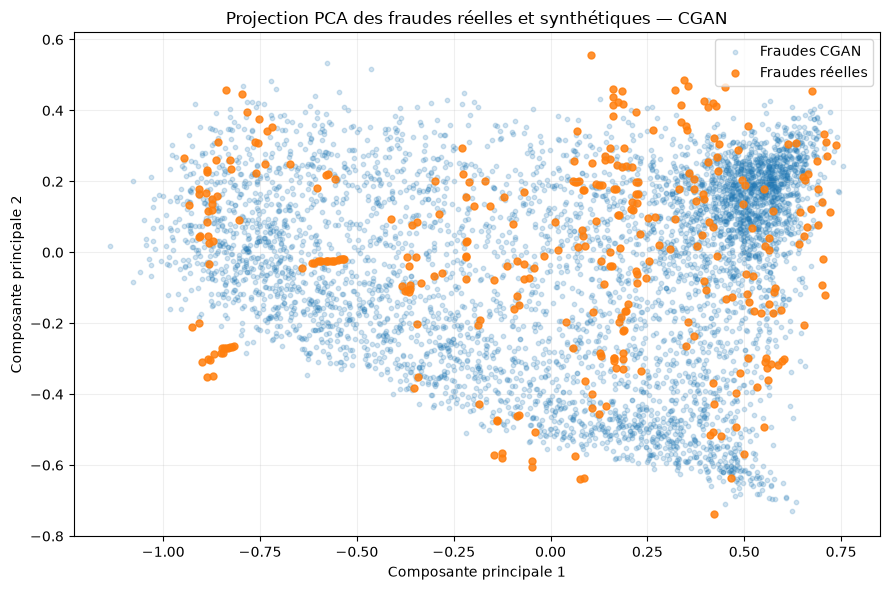

In [38]:
cgan_vis = (
    X_cgan_synthetic
    .sample(
        n=5000,
        random_state=42
    )
)

cgan_vis_pca = (
    pca_cgan.transform(
        cgan_vis
    )
)

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.scatter(
    cgan_vis_pca[:, 0],
    cgan_vis_pca[:, 1],
    s=10,
    alpha=0.20,
    label="Fraudes CGAN"
)

ax.scatter(
    real_fraud_pca[:, 0],
    real_fraud_pca[:, 1],
    s=25,
    alpha=0.85,
    label="Fraudes réelles"
)

ax.set_xlabel(
    "Composante principale 1"
)

ax.set_ylabel(
    "Composante principale 2"
)

ax.set_title(
    "Projection PCA des fraudes réelles et synthétiques — CGAN"
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "cgan_pca_real_vs_synthetic.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
cgan_corr_sample = (
    X_cgan_synthetic
    .sample(
        n=min(
            20000,
            len(X_cgan_synthetic)
        ),
        random_state=42
    )
)

real_corr = (
    X_real_fraud
    .corr(
        method="spearman"
    )
)

cgan_corr = (
    cgan_corr_sample
    .corr(
        method="spearman"
    )
)

corr_difference = np.abs(
    real_corr.to_numpy()
    -
    cgan_corr.to_numpy()
)

upper_triangle = (
    np.triu_indices_from(
        corr_difference,
        k=1
    )
)

cgan_corr_mae = float(
    corr_difference[
        upper_triangle
    ].mean()
)

print(
    "Erreur moyenne des corrélations de Spearman :",
    cgan_corr_mae
)

Erreur moyenne des corrélations de Spearman : 0.27383748914582146


In [36]:
cgan_fidelity_results = []

for column in X_train.columns:

    real_values = (
        X_real_fraud[column]
        .to_numpy()
    )

    synthetic_values = (
        X_cgan_synthetic[column]
        .to_numpy()
    )

    ks_stat = ks_2samp(
        real_values,
        synthetic_values
    ).statistic

    wasserstein = wasserstein_distance(
        real_values,
        synthetic_values
    )

    cgan_fidelity_results.append({
        "Feature": column,
        "KS_Statistic": ks_stat,
        "Wasserstein_Distance": wasserstein
    })

cgan_fidelity = pd.DataFrame(
    cgan_fidelity_results
)

display(
    cgan_fidelity
    .sort_values(
        "KS_Statistic",
        ascending=False
    )
    .head(10)
)

,Feature,KS_Statistic,Wasserstein_Distance
20,V20,0.541336,0.029512
27,V27,0.541005,0.044449
23,V23,0.517494,0.027676
21,V21,0.274140,0.017879
14,V14,0.271104,0.084263
28,V28,0.263691,0.017856
25,V25,0.262545,0.024006
8,V8,0.259760,0.026065
11,V11,0.232731,0.088411
12,V12,0.217943,0.057902


In [35]:
nn_real = NearestNeighbors(
    n_neighbors=2
)

nn_real.fit(
    X_real_fraud
)

real_nn_distances, _ = (
    nn_real.kneighbors(
        X_real_fraud
    )
)

real_reference_nn = (
    real_nn_distances[:, 1]
)

cgan_nn_sample = (
    X_cgan_synthetic
    .sample(
        n=min(
            5000,
            len(X_cgan_synthetic)
        ),
        random_state=42
    )
)

nn_to_real = NearestNeighbors(
    n_neighbors=1
)

nn_to_real.fit(
    X_real_fraud
)

synthetic_nn_distances, _ = (
    nn_to_real.kneighbors(
        cgan_nn_sample
    )
)

synthetic_nn_distances = (
    synthetic_nn_distances[:, 0]
)

print(
    "Médiane distance réel→réel :",
    np.median(
        real_reference_nn
    )
)

print(
    "Médiane distance CGAN→réel :",
    np.median(
        synthetic_nn_distances
    )
)

Médiane distance réel→réel : 0.23246914530944554
Médiane distance CGAN→réel : 0.35731427674812155


In [34]:
cgan_diversity_sample = (
    X_cgan_synthetic
    .sample(
        n=len(X_real_fraud),
        random_state=42
    )
)

real_pairwise = pdist(
    X_real_fraud.to_numpy()
)

cgan_pairwise = pdist(
    cgan_diversity_sample.to_numpy()
)

real_diversity = float(
    np.mean(
        real_pairwise
    )
)

cgan_diversity = float(
    np.mean(
        cgan_pairwise
    )
)

cgan_diversity_ratio = (
    cgan_diversity
    /
    real_diversity
)

print(
    "Distance moyenne réelle :",
    real_diversity
)

print(
    "Distance moyenne CGAN :",
    cgan_diversity
)

print(
    "Ratio diversité CGAN/Réel :",
    cgan_diversity_ratio
)

Distance moyenne réelle : 0.926863647990703
Distance moyenne CGAN : 0.8300530224367496
Ratio diversité CGAN/Réel : 0.8955503047683185


In [33]:
real_float32 = (
    X_real_fraud
    .astype(np.float32)
)

synthetic_float32 = (
    X_cgan_synthetic
    .astype(np.float32)
)

real_hashes = set(
    pd.util.hash_pandas_object(
        real_float32,
        index=False
    ).tolist()
)

synthetic_hashes = (
    pd.util.hash_pandas_object(
        synthetic_float32,
        index=False
    )
)

cgan_exact_copies = int(
    synthetic_hashes
    .isin(real_hashes)
    .sum()
)

print(
    "Copies exactes de fraudes réelles :",
    cgan_exact_copies
)

Copies exactes de fraudes réelles : 0


In [32]:
fraud_min = X_real_fraud.min()
fraud_max = X_real_fraud.max()

outside_fraud_bounds = (
    (X_cgan_synthetic < fraud_min)
    |
    (X_cgan_synthetic > fraud_max)
)

cgan_outside_count = int(
    outside_fraud_bounds
    .sum()
    .sum()
)

print(
    "Valeurs hors min/max des fraudes réelles :",
    cgan_outside_count
)

Valeurs hors min/max des fraudes réelles : 151405


In [31]:
cgan_nan = int(
    X_cgan_synthetic
    .isna()
    .sum()
    .sum()
)

cgan_inf = int(
    np.isinf(
        X_cgan_synthetic.to_numpy()
    ).sum()
)

cgan_duplicates = int(
    X_cgan_synthetic
    .duplicated()
    .sum()
)

print("NaN :", cgan_nan)
print("Infini :", cgan_inf)
print(
    "Doublons exacts :",
    cgan_duplicates
)

print(
    "Minimum généré :",
    X_cgan_synthetic
    .min()
    .min()
)

print(
    "Maximum généré :",
    X_cgan_synthetic
    .max()
    .max()
)

NaN : 0
Infini : 0
Doublons exacts : 0
Minimum généré : 0.0014016376
Maximum généré : 0.99977267


In [30]:
cgan_generated_array = (
    generate_cgan_samples(
        generator=cgan_generator,
        n_samples=N_SYNTHETIC_CGAN,
        latent_dim=LATENT_DIM,
        class_id=1
    )
)

X_cgan_synthetic = pd.DataFrame(
    cgan_generated_array,
    columns=X_train.columns
)

print(
    "Fraudes CGAN générées :",
    X_cgan_synthetic.shape
)

Fraudes CGAN générées : (197946, 30)


In [29]:
def generate_cgan_samples(
    generator,
    n_samples,
    latent_dim,
    class_id,
    batch_size=4096,
    seed=2027
):

    rng = np.random.default_rng(
        seed
    )

    generated_chunks = []

    class_vector = np.zeros(
        NUM_CLASSES,
        dtype=np.float32
    )

    class_vector[
        class_id
    ] = 1.0

    for start in range(
        0,
        n_samples,
        batch_size
    ):

        current_batch = min(
            batch_size,
            n_samples - start
        )

        noise = rng.normal(
            size=(
                current_batch,
                latent_dim
            )
        ).astype(np.float32)

        conditions = np.tile(
            class_vector,
            (
                current_batch,
                1
            )
        )

        generated = generator(
            [
                noise,
                conditions
            ],
            training=False
        ).numpy()

        generated_chunks.append(
            generated
        )

    return np.vstack(
        generated_chunks
    )

In [28]:
N_SYNTHETIC_CGAN = 197_946

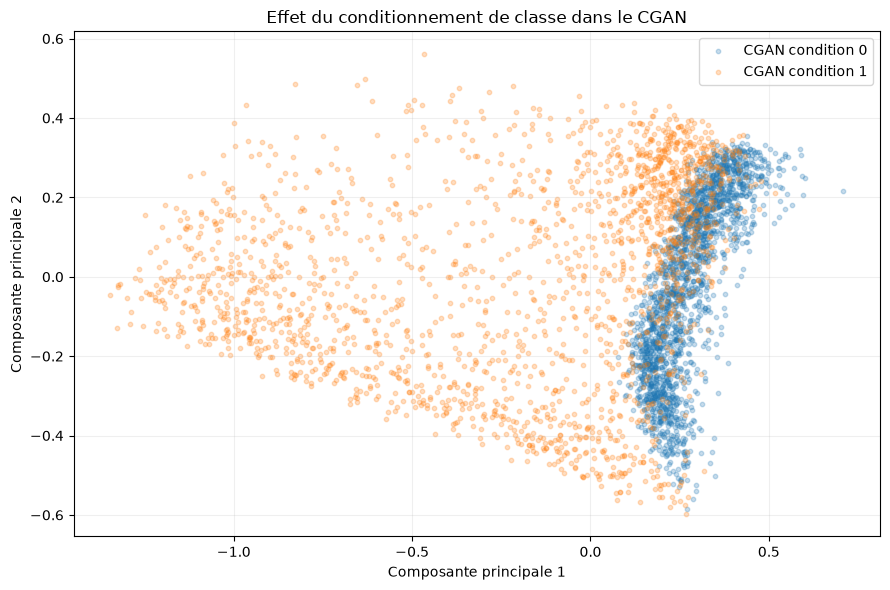

In [27]:
fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.scatter(
    generated_normal_pca[:, 0],
    generated_normal_pca[:, 1],
    s=10,
    alpha=0.25,
    label="CGAN condition 0"
)

ax.scatter(
    generated_fraud_pca[:, 0],
    generated_fraud_pca[:, 1],
    s=10,
    alpha=0.25,
    label="CGAN condition 1"
)

ax.set_xlabel(
    "Composante principale 1"
)

ax.set_ylabel(
    "Composante principale 2"
)

ax.set_title(
    "Effet du conditionnement de classe dans le CGAN"
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "cgan_conditioning_effect.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
real_normal_vis = (
    X_real_normal
    .sample(
        n=331,
        random_state=42
    )
)

real_balanced_vis = pd.concat(
    [
        real_normal_vis,
        X_real_fraud
    ],
    ignore_index=True
)

pca_condition = PCA(
    n_components=2
)

pca_condition.fit(
    real_balanced_vis
)

generated_normal_pca = (
    pca_condition.transform(
        generated_normal_test[:2000]
    )
)

generated_fraud_pca = (
    pca_condition.transform(
        generated_fraud_test[:2000]
    )
)

c:\Users\MSI\Desktop\fraud_detection_memoire\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\MSI\Desktop\fraud_detection_memoire\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


In [25]:
conditional_difference = float(
    np.mean(
        np.abs(
            generated_normal_test
            -
            generated_fraud_test
        )
    )
)

print(
    "Différence moyenne entre conditions 0 et 1 :",
    conditional_difference
)

Différence moyenne entre conditions 0 et 1 : 0.09742101281881332


In [24]:
condition_test_rng = (
    np.random.default_rng(
        2026
    )
)

condition_test_noise = (
    condition_test_rng.normal(
        size=(
            5000,
            LATENT_DIM
        )
    )
    .astype(np.float32)
)

normal_conditions = np.tile(
    np.array(
        [[1.0, 0.0]],
        dtype=np.float32
    ),
    (5000, 1)
)

fraud_conditions = np.tile(
    np.array(
        [[0.0, 1.0]],
        dtype=np.float32
    ),
    (5000, 1)
)

generated_normal_test = (
    cgan_generator(
        [
            condition_test_noise,
            normal_conditions
        ],
        training=False
    )
    .numpy()
)

generated_fraud_test = (
    cgan_generator(
        [
            condition_test_noise,
            fraud_conditions
        ],
        training=False
    )
    .numpy()
)

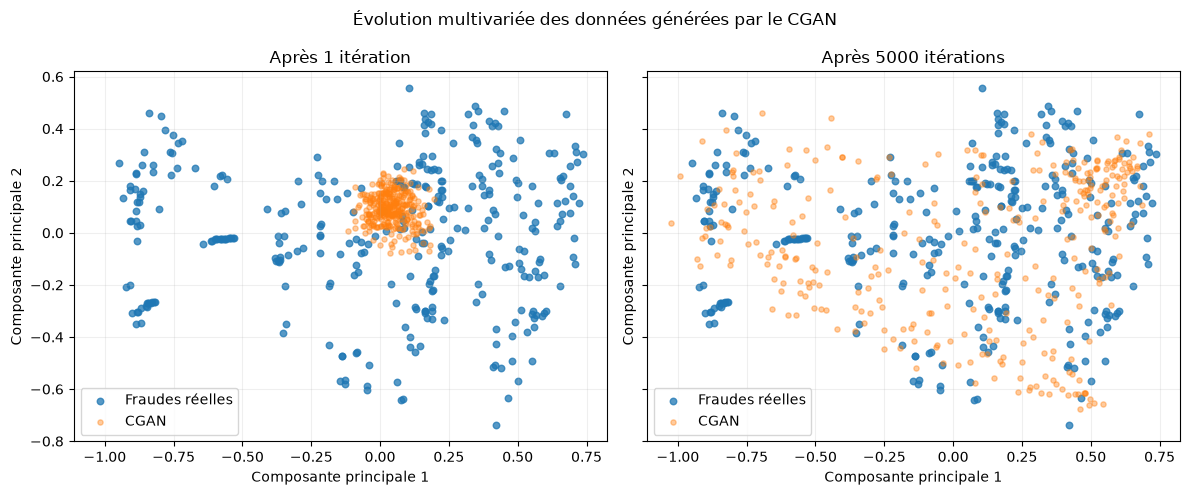

In [23]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5),
    sharex=True,
    sharey=True
)

for ax, generated, title in [
    (
        axes[0],
        cgan_1_pca,
        "Après 1 itération"
    ),
    (
        axes[1],
        cgan_5000_pca,
        "Après 5000 itérations"
    )
]:

    ax.scatter(
        real_fraud_pca[:, 0],
        real_fraud_pca[:, 1],
        s=22,
        alpha=0.75,
        label="Fraudes réelles"
    )

    ax.scatter(
        generated[:, 0],
        generated[:, 1],
        s=14,
        alpha=0.40,
        label="CGAN"
    )

    ax.set_title(title)
    ax.set_xlabel(
        "Composante principale 1"
    )
    ax.set_ylabel(
        "Composante principale 2"
    )
    ax.legend()
    ax.grid(alpha=0.2)

fig.suptitle(
    "Évolution multivariée des données générées par le CGAN"
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "cgan_pca_iteration_1_vs_5000.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
pca_cgan = PCA(
    n_components=2
)

real_fraud_pca = (
    pca_cgan.fit_transform(
        X_real_fraud
    )
)

cgan_1_pca = (
    pca_cgan.transform(
        cgan_snapshots[1]
    )
)

cgan_5000_pca = (
    pca_cgan.transform(
        cgan_snapshots[5000]
    )
)

c:\Users\MSI\Desktop\fraud_detection_memoire\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\MSI\Desktop\fraud_detection_memoire\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


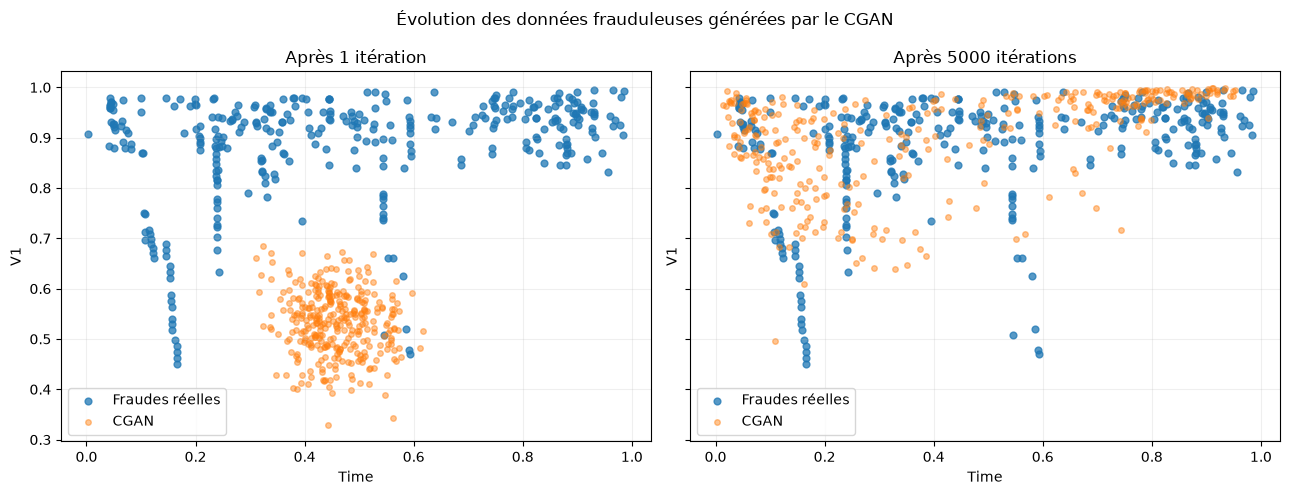

In [21]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
    sharex=True,
    sharey=True
)

# Réel
axes[0].scatter(
    X_real_fraud["Time"],
    X_real_fraud["V1"],
    s=24,
    alpha=0.75,
    label="Fraudes réelles"
)

# Généré itération 1
axes[0].scatter(
    cgan_snapshots[1][:, 0],
    cgan_snapshots[1][:, 1],
    s=16,
    alpha=0.45,
    label="CGAN"
)

axes[0].set_title(
    "Après 1 itération"
)

# Réel
axes[1].scatter(
    X_real_fraud["Time"],
    X_real_fraud["V1"],
    s=24,
    alpha=0.75,
    label="Fraudes réelles"
)

# Généré itération 5000
axes[1].scatter(
    cgan_snapshots[5000][:, 0],
    cgan_snapshots[5000][:, 1],
    s=16,
    alpha=0.45,
    label="CGAN"
)

axes[1].set_title(
    "Après 5000 itérations"
)

for ax in axes:

    ax.set_xlabel("Time")
    ax.set_ylabel("V1")
    ax.legend()
    ax.grid(alpha=0.20)

fig.suptitle(
    "Évolution des données frauduleuses générées par le CGAN"
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "cgan_time_v1_iteration_1_vs_5000.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

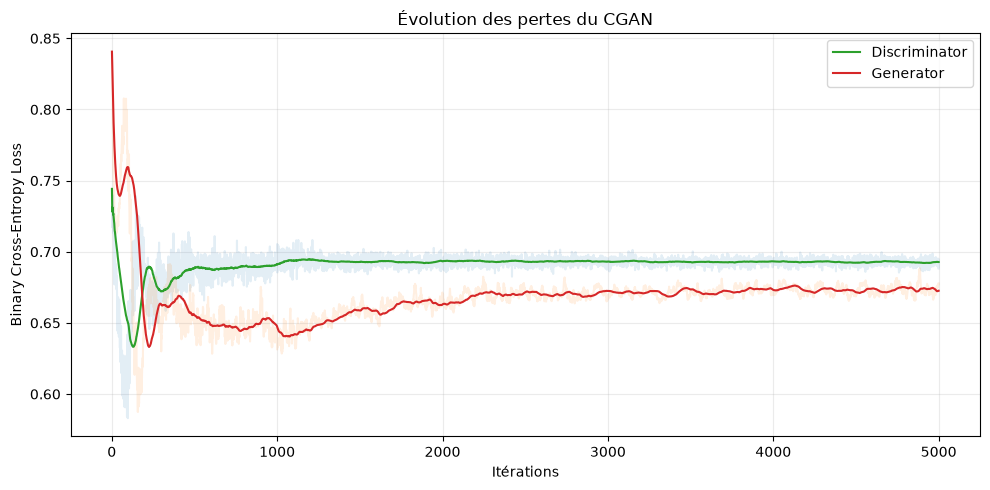

In [20]:
fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    cgan_history["Iteration"],
    cgan_history[
        "Discriminator_Loss"
    ],
    alpha=0.12
)

ax.plot(
    cgan_history["Iteration"],
    cgan_history[
        "Generator_Loss"
    ],
    alpha=0.12
)

ax.plot(
    cgan_history["Iteration"],
    cgan_history[
        "D_Loss_Smooth"
    ],
    label="Discriminator"
)

ax.plot(
    cgan_history["Iteration"],
    cgan_history[
        "G_Loss_Smooth"
    ],
    label="Generator"
)

ax.set_xlabel(
    "Itérations"
)

ax.set_ylabel(
    "Binary Cross-Entropy Loss"
)

ax.set_title(
    "Évolution des pertes du CGAN"
)

ax.legend()

ax.grid(
    alpha=0.25
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "cgan_training_losses.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
cgan_history = pd.DataFrame({
    "Iteration":
        np.arange(
            1,
            N_STEPS + 1
        ),

    "Discriminator_Loss":
        cgan_d_losses,

    "Generator_Loss":
        cgan_g_losses
})

cgan_history[
    "D_Loss_Smooth"
] = (
    cgan_history[
        "Discriminator_Loss"
    ]
    .rolling(
        window=100,
        min_periods=1
    )
    .mean()
)

cgan_history[
    "G_Loss_Smooth"
] = (
    cgan_history[
        "Generator_Loss"
    ]
    .rolling(
        window=100,
        min_periods=1
    )
    .mean()
)

In [18]:
rng = np.random.default_rng(
    SEED
)

cgan_d_losses = []
cgan_g_losses = []

for step in range(
    1,
    N_STEPS + 1
):

    # ----------------------------
    # 32 normales
    # ----------------------------

    normal_indices = rng.integers(
        low=0,
        high=len(normal_array),
        size=HALF_BATCH
    )

    normal_batch = normal_array[
        normal_indices
    ]

    # ----------------------------
    # 32 fraudes
    # ----------------------------

    fraud_indices = rng.integers(
        low=0,
        high=len(fraud_array),
        size=HALF_BATCH
    )

    fraud_batch = fraud_array[
        fraud_indices
    ]

    # ----------------------------
    # Construire batch réel
    # ----------------------------

    real_batch = np.vstack(
        [
            normal_batch,
            fraud_batch
        ]
    ).astype(np.float32)

    class_ids = np.concatenate(
        [
            np.zeros(
                HALF_BATCH,
                dtype=np.int32
            ),
            np.ones(
                HALF_BATCH,
                dtype=np.int32
            )
        ]
    )

    # Mélanger
    permutation = rng.permutation(
        BATCH_SIZE
    )

    real_batch = real_batch[
        permutation
    ]

    class_ids = class_ids[
        permutation
    ]

    real_batch_tensor = (
        tf.convert_to_tensor(
            real_batch
        )
    )

    class_ids_tensor = (
        tf.convert_to_tensor(
            class_ids
        )
    )

    d_loss, g_loss = cgan_train_step(
        real_batch_tensor,
        class_ids_tensor
    )

    d_value = float(
        d_loss.numpy()
    )

    g_value = float(
        g_loss.numpy()
    )

    cgan_d_losses.append(
        d_value
    )

    cgan_g_losses.append(
        g_value
    )

    if (
        np.isnan(d_value)
        or np.isnan(g_value)
        or np.isinf(d_value)
        or np.isinf(g_value)
    ):
        raise RuntimeError(
            f"Instabilité numérique à l'itération {step}"
        )

    if step in SNAPSHOT_STEPS:

        snapshot = cgan_generator(
            [
                fixed_noise,
                fixed_fraud_condition
            ],
            training=False
        ).numpy()

        cgan_snapshots[
            step
        ] = snapshot.copy()

    if (
        step == 1
        or step % 500 == 0
    ):

        print(
            f"Iteration {step:4d}/{N_STEPS} "
            f"| D_loss = {d_value:.4f} "
            f"| G_loss = {g_value:.4f}"
        )

Iteration    1/5000 | D_loss = 0.7442 | G_loss = 0.8406
Iteration  500/5000 | D_loss = 0.6958 | G_loss = 0.6517
Iteration 1000/5000 | D_loss = 0.7054 | G_loss = 0.6313
Iteration 1500/5000 | D_loss = 0.6955 | G_loss = 0.6577
Iteration 2000/5000 | D_loss = 0.6938 | G_loss = 0.6695
Iteration 2500/5000 | D_loss = 0.6996 | G_loss = 0.6722
Iteration 3000/5000 | D_loss = 0.6898 | G_loss = 0.6688
Iteration 3500/5000 | D_loss = 0.6905 | G_loss = 0.6721
Iteration 4000/5000 | D_loss = 0.6953 | G_loss = 0.6717
Iteration 4500/5000 | D_loss = 0.6942 | G_loss = 0.6687
Iteration 5000/5000 | D_loss = 0.6882 | G_loss = 0.6778


In [17]:
snapshot_rng = np.random.default_rng(
    SEED
)

fixed_noise = snapshot_rng.normal(
    size=(
        331,
        LATENT_DIM
    )
).astype(np.float32)

fixed_fraud_condition = np.tile(
    np.array(
        [[0.0, 1.0]],
        dtype=np.float32
    ),
    (
        331,
        1
    )
)

SNAPSHOT_STEPS = [
    1,
    100,
    500,
    1000,
    2500,
    5000
]

cgan_snapshots = {}

In [16]:
@tf.function
def cgan_train_step(
    real_batch,
    class_ids
):

    batch_size = tf.shape(real_batch)[0]

    class_ids = tf.cast(
        class_ids,
        tf.int32
    )

    class_onehot = tf.one_hot(
        class_ids,
        depth=NUM_CLASSES
    )

    # ======================================
    # 1. DISCRIMINATOR
    # ======================================

    noise = tf.random.normal(
        shape=(
            batch_size,
            LATENT_DIM
        )
    )

    with tf.GradientTape() as d_tape:

        fake_batch = cgan_generator(
            [
                noise,
                class_onehot
            ],
            training=True
        )

        real_prediction = cgan_discriminator(
            [
                real_batch,
                class_onehot
            ],
            training=True
        )

        fake_prediction = cgan_discriminator(
            [
                fake_batch,
                class_onehot
            ],
            training=True
        )

        real_loss = bce(
            tf.ones_like(
                real_prediction
            ),
            real_prediction
        )

        fake_loss = bce(
            tf.zeros_like(
                fake_prediction
            ),
            fake_prediction
        )

        d_loss = (
            real_loss + fake_loss
        ) / 2.0

    d_gradients = d_tape.gradient(
        d_loss,
        cgan_discriminator.trainable_variables
    )

    cgan_discriminator_optimizer.apply_gradients(
        zip(
            d_gradients,
            cgan_discriminator.trainable_variables
        )
    )

    # ======================================
    # 2. GENERATOR
    # ======================================

    noise = tf.random.normal(
        shape=(
            batch_size,
            LATENT_DIM
        )
    )

    with tf.GradientTape() as g_tape:

        fake_batch = cgan_generator(
            [
                noise,
                class_onehot
            ],
            training=True
        )

        fake_prediction = cgan_discriminator(
            [
                fake_batch,
                class_onehot
            ],
            training=False
        )

        g_loss = bce(
            tf.ones_like(
                fake_prediction
            ),
            fake_prediction
        )

    g_gradients = g_tape.gradient(
        g_loss,
        cgan_generator.trainable_variables
    )

    cgan_generator_optimizer.apply_gradients(
        zip(
            g_gradients,
            cgan_generator.trainable_variables
        )
    )

    return d_loss, g_loss

In [15]:
bce = keras.losses.BinaryCrossentropy()

cgan_generator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE_G,
    beta_1=BETA_1
)

cgan_discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE_D,
    beta_1=BETA_1
)

In [14]:
same_noise = tf.random.normal(
    shape=(1, LATENT_DIM)
)

normal_condition = tf.one_hot(
    [0],
    depth=NUM_CLASSES
)

fraud_condition = tf.one_hot(
    [1],
    depth=NUM_CLASSES
)

before_normal = cgan_generator(
    [same_noise, normal_condition],
    training=False
)

before_fraud = cgan_generator(
    [same_noise, fraud_condition],
    training=False
)

print(
    "Différence moyenne avant entraînement :",
    tf.reduce_mean(
        tf.abs(
            before_normal - before_fraud
        )
    ).numpy()
)

Différence moyenne avant entraînement : 0.010154477


In [13]:
test_noise = tf.random.normal(
    shape=(5, LATENT_DIM)
)

test_fraud_condition = tf.one_hot(
    [1, 1, 1, 1, 1],
    depth=NUM_CLASSES
)

test_fake_fraud = cgan_generator(
    [
        test_noise,
        test_fraud_condition
    ],
    training=False
)

print("Forme :", test_fake_fraud.shape)

print(
    "Minimum :",
    tf.reduce_min(
        test_fake_fraud
    ).numpy()
)

print(
    "Maximum :",
    tf.reduce_max(
        test_fake_fraud
    ).numpy()
)

Forme : (5, 30)
Minimum : 0.2639009
Maximum : 0.6810903


In [12]:
cgan_discriminator = build_cgan_discriminator()

cgan_discriminator.summary()

Model: "CGAN_Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ transaction         │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_condition     │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 32)        │          0 │ transaction[0][0… │
│ (Concatenate)       │                   │            │ class_condition[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128)       │      4,224 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 128)       │          0 │ dense_3[0][0]     │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ leaky_re_lu_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_4       │ (None, 64)        │          0 │ dense_4[0][0]     │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ leaky_re_lu_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 32)        │      2,080 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_5       │ (None, 32)        │          0 │ dense_5[0][0]     │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ real_or_fake        │ (None, 1)         │         33 │ leaky_re_lu_5[0]… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,593 (57.00 KB)

 Trainable params: 14,593 (57.00 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
def build_cgan_discriminator():

    transaction_input = keras.Input(
        shape=(N_FEATURES,),
        name="transaction"
    )

    class_input = keras.Input(
        shape=(NUM_CLASSES,),
        name="class_condition"
    )

    x = layers.Concatenate()(
        [
            transaction_input,
            class_input
        ]
    )

    x = layers.Dense(128)(x)
    x = layers.LeakyReLU(
        negative_slope=0.2
    )(x)
    x = layers.Dropout(0.30)(x)

    x = layers.Dense(64)(x)
    x = layers.LeakyReLU(
        negative_slope=0.2
    )(x)
    x = layers.Dropout(0.30)(x)

    x = layers.Dense(32)(x)
    x = layers.LeakyReLU(
        negative_slope=0.2
    )(x)

    output = layers.Dense(
        1,
        activation="sigmoid",
        name="real_or_fake"
    )(x)

    model = keras.Model(
        inputs=[
            transaction_input,
            class_input
        ],
        outputs=output,
        name="CGAN_Discriminator"
    )

    return model

In [10]:
cgan_generator = build_cgan_generator()

cgan_generator.summary()

Model: "CGAN_Generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ noise (InputLayer)  │ (None, 30)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_condition     │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32)        │          0 │ noise[0][0],      │
│ (Concatenate)       │                   │            │ class_condition[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      2,112 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 64)        │          0 │ dense[0][0]       │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64)        │        256 │ leaky_re_lu[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │      8,320 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 128)       │          0 │ dense_1[0][0]     │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ leaky_re_lu_1[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 64)        │          0 │ dense_2[0][0]     │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ synthetic_transact… │ (None, 30)        │      1,950 │ leaky_re_lu_2[0]… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,406 (83.62 KB)

 Trainable params: 21,022 (82.12 KB)

 Non-trainable params: 384 (1.50 KB)

In [9]:
def build_cgan_generator():

    noise_input = keras.Input(
        shape=(LATENT_DIM,),
        name="noise"
    )

    class_input = keras.Input(
        shape=(NUM_CLASSES,),
        name="class_condition"
    )

    x = layers.Concatenate()(
        [noise_input, class_input]
    )

    x = layers.Dense(64)(x)
    x = layers.LeakyReLU(
        negative_slope=0.2
    )(x)
    x = layers.BatchNormalization()(x)

    x = layers.Dense(128)(x)
    x = layers.LeakyReLU(
        negative_slope=0.2
    )(x)
    x = layers.BatchNormalization()(x)

    x = layers.Dense(64)(x)
    x = layers.LeakyReLU(
        negative_slope=0.2
    )(x)

    output = layers.Dense(
        N_FEATURES,
        activation="sigmoid",
        name="synthetic_transaction"
    )(x)

    model = keras.Model(
        inputs=[
            noise_input,
            class_input
        ],
        outputs=output,
        name="CGAN_Generator"
    )

    return model

In [8]:
N_FEATURES = X_train.shape[1]

NUM_CLASSES = 2

LATENT_DIM = 30
BATCH_SIZE = 64
HALF_BATCH = BATCH_SIZE // 2

N_STEPS = 5000

LEARNING_RATE_G = 0.0002
LEARNING_RATE_D = 0.0002
BETA_1 = 0.5

print("Features :", N_FEATURES)
print("Classes :", NUM_CLASSES)
print("Latent dim :", LATENT_DIM)
print("Batch :", BATCH_SIZE)
print("Iterations :", N_STEPS)

Features : 30
Classes : 2
Latent dim : 30
Batch : 64
Iterations : 5000


In [7]:
normal_array = X_real_normal.to_numpy(
    dtype=np.float32
)

fraud_array = X_real_fraud.to_numpy(
    dtype=np.float32
)

print(normal_array.shape)
print(fraud_array.shape)

(198277, 30)
(331, 30)


## Principe du conditionnement

Un CGAN reçoit une information de classe en plus des données habituelles.

Le générateur reçoit :

`bruit aléatoire + classe demandée`

Le discriminateur reçoit :

`transaction + classe associée`

Le modèle apprend ainsi deux distributions conditionnelles :

- P(X | Class = 0)
- P(X | Class = 1)

Après l'entraînement, la classe 1 sera fournie au générateur afin de
produire uniquement des transactions frauduleuses synthétiques.

In [6]:
X_real_normal = (
    X_train.loc[y_train == 0]
    .reset_index(drop=True)
)

X_real_fraud = (
    X_train.loc[y_train == 1]
    .reset_index(drop=True)
)

print("Normales :", X_real_normal.shape)
print("Fraudes :", X_real_fraud.shape)

Normales : (198277, 30)
Fraudes : (331, 30)


In [5]:
X_train = pd.read_parquet(
    PROCESSED_DIR / "X_train.parquet"
)

y_train = pd.read_parquet(
    PROCESSED_DIR / "y_train.parquet"
)["Class"]

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("\nRépartition :")
print(y_train.value_counts().sort_index())

X_train : (198608, 30)
y_train : (198608,)

Répartition :
Class
0    198277
1       331
Name: count, dtype: int64


## Chargement des données Train

In [4]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
SYNTHETIC_DIR = PROJECT_ROOT / "results" / "synthetic"
MODELS_DIR = PROJECT_ROOT / "models"

for directory in [
    FIGURES_DIR,
    METRICS_DIR,
    SYNTHETIC_DIR,
    MODELS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Projet :", PROJECT_ROOT)

Projet : c:\Users\MSI\Desktop\fraud_detection_memoire


In [3]:
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

print("Seed :", SEED)

Seed : 42


In [2]:
print("TensorFlow :", tf.__version__)
print("Keras :", keras.__version__)

TensorFlow : 2.21.0
Keras : 3.15.1


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

from scipy.stats import ks_2samp, wasserstein_distance
from scipy.spatial.distance import pdist

# 06 — Génération conditionnelle de transactions par CGAN

Ce notebook met en œuvre un Conditional Generative Adversarial Network
(CGAN) afin de générer des transactions synthétiques en contrôlant
explicitement la classe produite.

Contrairement au Vanilla GAN, le générateur et le discriminateur
reçoivent également une information de classe :

- classe 0 : transaction normale ;
- classe 1 : transaction frauduleuse.

Le CGAN est entraîné exclusivement à partir de l'ensemble Train.
Les ensembles Validation et Test restent totalement exclus du processus
de génération.

L'objectif final est de demander au générateur entraîné de produire
uniquement de nouvelles transactions frauduleuses en imposant
la condition `Class = 1`.